# Simulación de un Modelo Oculto de Markov (HMM)
**Monitoreo del estado de una máquina industrial a partir de su vibración**
Actividad didáctica 2-M2 · IU Digital · Autor: David Castro

**Problema:** el estado interno de la máquina (Sano, Desgaste, Crítico) no se observa directamente. Lo que se mide es el nivel de vibración (Baja, Media, Alta). El HMM simula la evolución de la máquina y permite inferir el estado oculto a partir de las vibraciones.

**Componentes del HMM:** probabilidades iniciales π, matriz de transición A y matriz de emisión B.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

ESTADOS = ["Sano", "Desgaste", "Critico"]
OBSERV = ["Baja", "Media", "Alta"]

## 1. Definición del modelo

In [2]:
# Probabilidades iniciales (pi)
PI = np.array([0.80, 0.18, 0.02])

# Matriz de transición A[i, j] = P(estado_{t+1}=j | estado_t=i)
A = np.array([
    [0.92, 0.07, 0.01],
    [0.05, 0.85, 0.10],
    [0.40, 0.10, 0.50],
])

# Matriz de emisión B[i, k] = P(observación=k | estado=i)
B = np.array([
    [0.75, 0.20, 0.05],
    [0.20, 0.55, 0.25],
    [0.05, 0.25, 0.70],
])

# Validación: cada distribución debe sumar 1
assert np.isclose(PI.sum(), 1.0) and np.allclose(A.sum(axis=1), 1.0) and np.allclose(B.sum(axis=1), 1.0)

display(pd.DataFrame([PI], columns=ESTADOS, index=["π"]))
display(pd.DataFrame(A, index=ESTADOS, columns=ESTADOS).rename_axis("Transición A"))
display(pd.DataFrame(B, index=ESTADOS, columns=["Vib. " + o for o in OBSERV]).rename_axis("Emisión B"))

,Sano,Desgaste,Critico
π,0.8,0.18,0.02


,Sano,Desgaste,Critico
Transición A,,,
Sano,0.92,0.07,0.01
Desgaste,0.05,0.85,0.10
Critico,0.40,0.10,0.50


,Vib. Baja,Vib. Media,Vib. Alta
Emisión B,,,
Sano,0.75,0.20,0.05
Desgaste,0.20,0.55,0.25
Critico,0.05,0.25,0.70


## 2. Funciones: simulación, forward, Viterbi y distribución estacionaria

In [3]:
def simular(T, rng):
    """Genera (estados ocultos, observaciones) con distribuciones categóricas."""
    z = np.empty(T, dtype=int)
    x = np.empty(T, dtype=int)
    z[0] = rng.choice(3, p=PI)
    x[0] = rng.choice(3, p=B[z[0]])
    for t in range(1, T):
        z[t] = rng.choice(3, p=A[z[t - 1]])
        x[t] = rng.choice(3, p=B[z[t]])
    return z, x


def forward(x):
    """Algoritmo forward escalado: log-verosimilitud y filtrado P(z_t | x_1..t)."""
    T = len(x)
    alfa = np.zeros((T, 3)); c = np.zeros(T)
    a = PI * B[:, x[0]]
    c[0] = a.sum(); alfa[0] = a / c[0]
    for t in range(1, T):
        a = (alfa[t - 1] @ A) * B[:, x[t]]
        c[t] = a.sum(); alfa[t] = a / c[t]
    return np.log(c).sum(), alfa


def viterbi(x):
    """Secuencia de estados ocultos más probable dada la observación."""
    T = len(x)
    d = np.zeros((T, 3)); psi = np.zeros((T, 3), dtype=int)
    d[0] = np.log(PI) + np.log(B[:, x[0]])
    for t in range(1, T):
        m = d[t - 1][:, None] + np.log(A)
        psi[t] = m.argmax(axis=0)
        d[t] = m.max(axis=0) + np.log(B[:, x[t]])
    z = np.zeros(T, dtype=int)
    z[-1] = d[-1].argmax()
    for t in range(T - 2, -1, -1):
        z[t] = psi[t + 1, z[t + 1]]
    return z


def estacionaria():
    """Distribución estacionaria teórica de la cadena (autovector izquierdo de A)."""
    w, v = np.linalg.eig(A.T)
    p = np.real(v[:, np.argmin(np.abs(w - 1))])
    return p / p.sum()

## 3. Parámetros de la simulación
Cambia `SEMILLA` para obtener otra secuencia distinta.

In [4]:
PASOS = 200       # longitud de la secuencia
SEMILLA = 42      # cambia este valor para otra simulación
CORRIDAS = 500    # réplicas Monte Carlo

rng = np.random.default_rng(SEMILLA)

## 4. Simulación individual

In [5]:
z, x = simular(PASOS, rng)
ll, alfa = forward(x)
zv = viterbi(x)
acc_v = (zv == z).mean()
acc_f = (alfa.argmax(axis=1) == z).mean()

print("Estados ocultos (primeros 30):", " ".join(ESTADOS[i][0] for i in z[:30]))
print("Observaciones   (primeras 30):", " ".join(OBSERV[i][0] for i in x[:30]))
print("Viterbi         (primeros 30):", " ".join(ESTADOS[i][0] for i in zv[:30]))
print(f"\nLog-verosimilitud de la secuencia: {ll:.2f}")
print(f"Precisión Viterbi: {acc_v:.3f} | Precisión filtrado forward: {acc_f:.3f}")

tabla = pd.DataFrame({
    "t": range(PASOS),
    "estado_oculto": [ESTADOS[i] for i in z],
    "observacion": [OBSERV[i] for i in x],
    "viterbi": [ESTADOS[i] for i in zv],
    "P_sano": alfa[:, 0].round(4), "P_desgaste": alfa[:, 1].round(4), "P_critico": alfa[:, 2].round(4),
})
tabla.head(15)

Estados ocultos (primeros 30): S S S S S S S S S S S D D D D D D D D D D D D D D D D D D D
Observaciones   (primeras 30): B B A M B M M B B B B A B B M A M B M M A M A M B B M A M B
Viterbi         (primeros 30): S S S S S S S S S S S S S S D D D D D D D D D D D D D D D D

Log-verosimilitud de la secuencia: -191.50
Precisión Viterbi: 0.810 | Precisión filtrado forward: 0.725


,t,estado_oculto,observacion,viterbi,P_sano,P_desgaste,P_critico
0,0,Sano,Baja,Sano,0.9419,0.0565,0.0016
1,1,Sano,Baja,Sano,0.9651,0.0338,0.0012
2,2,Sano,Alta,Sano,0.5696,0.3084,0.1220
3,3,Sano,Media,Sano,0.3737,0.5489,0.0774
4,4,Sano,Baja,Sano,0.7419,0.2462,0.0120
5,5,Sano,Media,Sano,0.4764,0.4913,0.0324
6,6,Sano,Media,Sano,0.2625,0.6891,0.0483
7,7,Sano,Baja,Sano,0.6363,0.3499,0.0137
8,8,Sano,Baja,Sano,0.8652,0.1302,0.0046
9,9,Sano,Baja,Sano,0.9444,0.0538,0.0019


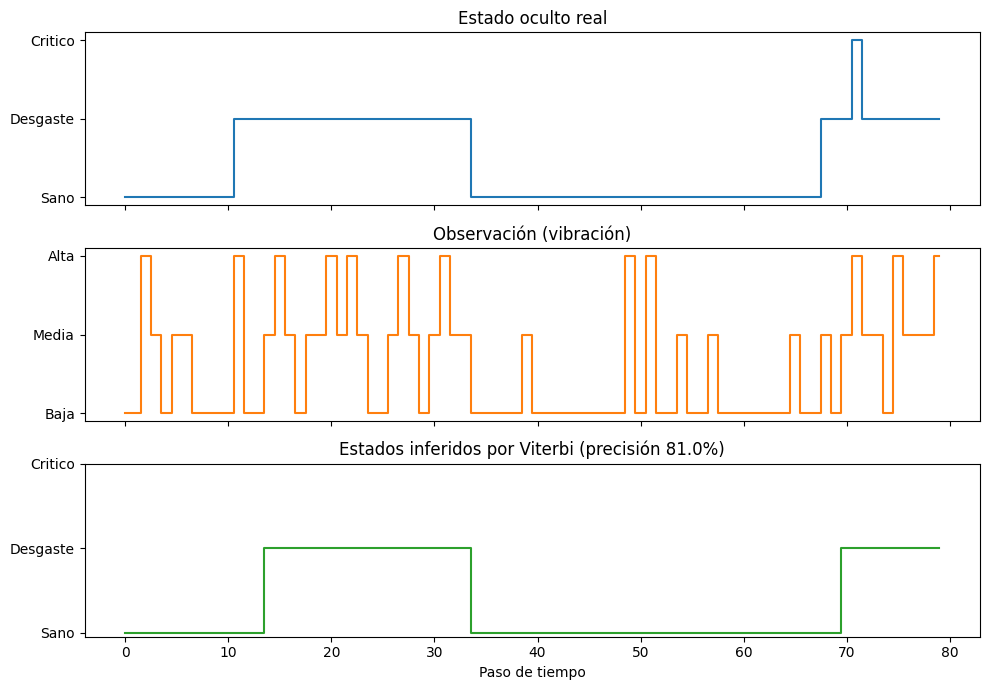

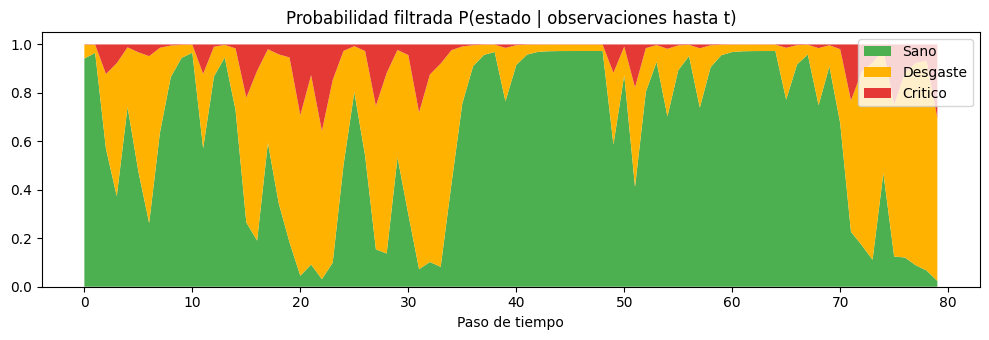

In [6]:
N = min(80, PASOS); t = np.arange(N)
fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
ax[0].step(t, z[:N], where="mid", color="tab:blue"); ax[0].set_yticks(range(3)); ax[0].set_yticklabels(ESTADOS); ax[0].set_title("Estado oculto real")
ax[1].step(t, x[:N], where="mid", color="tab:orange"); ax[1].set_yticks(range(3)); ax[1].set_yticklabels(OBSERV); ax[1].set_title("Observación (vibración)")
ax[2].step(t, zv[:N], where="mid", color="tab:green"); ax[2].set_yticks(range(3)); ax[2].set_yticklabels(ESTADOS)
ax[2].set_title(f"Estados inferidos por Viterbi (precisión {acc_v:.1%})"); ax[2].set_xlabel("Paso de tiempo")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.stackplot(t, alfa[:N].T, labels=ESTADOS, colors=["#4caf50", "#ffb300", "#e53935"])
ax.set_title("Probabilidad filtrada P(estado | observaciones hasta t)"); ax.set_xlabel("Paso de tiempo"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## 5. Análisis Monte Carlo
Se repite la simulación muchas veces para comparar las frecuencias simuladas con la teoría.

In [7]:
accs, frec_est, frec_obs = [], np.zeros(3), np.zeros(3)
trans = np.zeros((3, 3)); emis = np.zeros((3, 3))
for _ in range(CORRIDAS):
    zz, xx = simular(PASOS, rng)
    accs.append((viterbi(xx) == zz).mean())
    frec_est += np.bincount(zz, minlength=3)
    frec_obs += np.bincount(xx, minlength=3)
    for a_, b_ in zip(zz[:-1], zz[1:]): trans[a_, b_] += 1
    for s_, o_ in zip(zz, xx): emis[s_, o_] += 1

frec_est /= frec_est.sum(); frec_obs /= frec_obs.sum()
A_hat = trans / trans.sum(axis=1, keepdims=True)
B_hat = emis / emis.sum(axis=1, keepdims=True)
pi_teo = estacionaria(); obs_teo = pi_teo @ B

print(f"Precisión Viterbi media: {np.mean(accs):.3f} (desv. {np.std(accs):.3f})")
display(pd.DataFrame({"Simulada": frec_est, "Estacionaria teórica": pi_teo}, index=ESTADOS).round(3))
display(pd.DataFrame({"Simulada": frec_obs, "Teórica": obs_teo}, index=["Vib. " + o for o in OBSERV]).round(3))
print("Error máx. |A_hat - A| =", round(float(np.abs(A_hat - A).max()), 4))
print("Error máx. |B_hat - B| =", round(float(np.abs(B_hat - B).max()), 4))

Precisión Viterbi media: 0.818 (desv. 0.052)


,Simulada,Estacionaria teórica
Sano,0.596,0.594
Desgaste,0.327,0.329
Critico,0.077,0.078


,Simulada,Teórica
Vib. Baja,0.516,0.515
Vib. Media,0.319,0.319
Vib. Alta,0.165,0.166


Error máx. |A_hat - A| = 0.0051
Error máx. |B_hat - B| = 0.0069


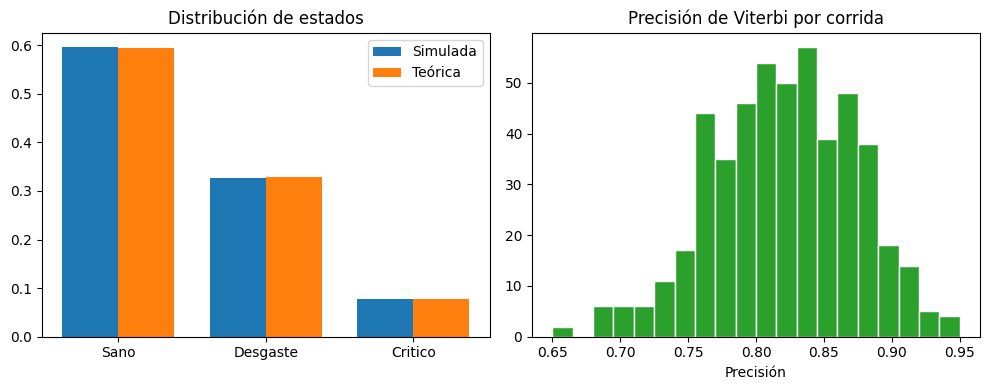

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
idx = np.arange(3); wd = 0.38
ax[0].bar(idx - wd/2, frec_est, wd, label="Simulada"); ax[0].bar(idx + wd/2, pi_teo, wd, label="Teórica")
ax[0].set_xticks(idx); ax[0].set_xticklabels(ESTADOS); ax[0].set_title("Distribución de estados"); ax[0].legend()
ax[1].hist(accs, bins=20, color="tab:green", edgecolor="white"); ax[1].set_title("Precisión de Viterbi por corrida"); ax[1].set_xlabel("Precisión")
plt.tight_layout(); plt.show()

## 6. Conclusiones
- El HMM representa la máquina con un estado interno no observable y vibraciones visibles, y permite inferir el estado a partir de ellas.
- Las frecuencias simuladas coinciden con la distribución estacionaria teórica (diferencias menores a un punto porcentual).
- Viterbi recupera cerca del 82 % de los estados reales; los errores se concentran en los cambios de estado porque las emisiones de estados vecinos se solapan.
- Al cambiar `SEMILLA` se obtienen secuencias distintas con estadísticas globales estables.
- Limitación: las probabilidades se asumieron con criterio técnico; con datos reales se podrían ajustar con Baum-Welch.